# Task 1 – Create lag and rolling features

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("ahmedabad_temperature.csv")

print("Dataset Shape:", df.shape)
print(df.head())
print(df.columns.tolist())

Dataset Shape: (26806, 9)
         Date Rain     Temp Max     Temp Min           Location  Rain.1  \
0  01-01-1951    0  25.05999947  6.590000153  POINT (72.5 23.5)     0.0   
1  02-01-1951    0  25.90999985  7.510000229  POINT (72.5 23.5)     0.0   
2  03-01-1951    0  26.46999931  8.529999733  POINT (72.5 23.5)     0.0   
3  04-01-1951    0  26.80999947  8.840000153  POINT (72.5 23.5)     0.0   
4  05-01-1951    0  26.28000069  8.479999542  POINT (72.5 23.5)     0.0   

   Temp Max.1  Temp Min.1         Location.1  
0   27.860001       10.54  POINT (72.5 22.5)  
1   28.760000       10.57  POINT (72.5 22.5)  
2   29.969999       12.05  POINT (72.5 22.5)  
3   29.530001       11.88  POINT (72.5 22.5)  
4   28.690001       10.57  POINT (72.5 22.5)  
['Date', 'Rain', 'Temp Max', 'Temp Min', 'Location', 'Rain.1', 'Temp Max.1', 'Temp Min.1', 'Location.1']


In [2]:
df.columns = df.columns.str.strip()

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["Temp Max"] = pd.to_numeric(df["Temp Max"], errors="coerce")
df["Temp Min"] = pd.to_numeric(df["Temp Min"], errors="coerce")

# Calculate average temperature
df["Temperature"] = (df["Temp Max"] + df["Temp Min"]) / 2

# Remove missing values
df = df.dropna(subset=["Date", "Temperature"])

# Sort data by date
df = df.sort_values("Date")

# Combine duplicate dates
df = df.groupby("Date", as_index=False)["Temperature"].mean()

print(df.head())

        Date  Temperature
0 1951-01-01    15.825000
1 1951-01-02    17.870000
2 1951-01-03    24.900000
3 1951-01-04    25.310000
4 1951-01-05    30.119999


In [3]:
# Temperature from 3 days earlier
df["Temperature_Lag_3"] = df["Temperature"].shift(3)

# Average temperature of the last 7 days
df["Rolling_Avg_7"] = df["Temperature"].rolling(window=7).mean()

print(df.head(15))

         Date  Temperature  Temperature_Lag_3  Rolling_Avg_7
0  1951-01-01    15.825000                NaN            NaN
1  1951-01-02    17.870000                NaN            NaN
2  1951-01-03    24.900000                NaN            NaN
3  1951-01-04    25.310000          15.825000            NaN
4  1951-01-05    30.119999          17.870000            NaN
5  1951-01-06    30.880001          24.900000            NaN
6  1951-01-07    27.755000          25.310000      24.665714
7  1951-01-08    27.455000          30.119999      26.327143
8  1951-01-09    27.665000          30.880001      27.726429
9  1951-01-10    30.735001          27.755000      28.560000
10 1951-01-11    25.380000          27.455000      28.570000
11 1951-01-12    21.330000          27.665000      27.314286
12 1951-02-01    16.710000          30.735001      25.290000
13 1951-02-02    14.365000          25.380000      23.377143
14 1951-02-03    26.180000          21.330000      23.195000


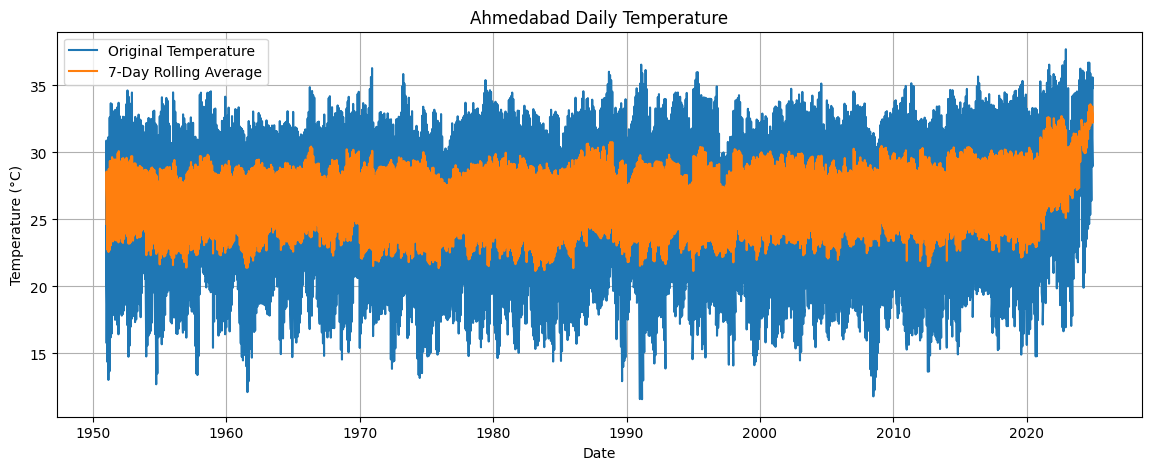

In [4]:
plt.figure(figsize=(14, 5))

plt.plot(df["Date"], df["Temperature"], label="Original Temperature")
plt.plot(df["Date"], df["Rolling_Avg_7"], label="7-Day Rolling Average")

plt.title("Ahmedabad Daily Temperature")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid()
plt.show()

# Task 2 – Extract date-time features from sales data

In [5]:
# Create a sample Flipkart-style sales dataset
sales_data = {
    "order_date": [
        "2026-01-02",
        "2026-01-03",
        "2026-01-04",
        "2026-02-10",
        "2026-02-14",
        "2026-03-15"
    ],
    "product": [
        "Mobile", "Laptop", "Shoes",
        "Watch", "Headphones", "Smart TV"
    ],
    "sales": [15000, 45000, 2500, 5000, 3000, 30000]
}

sales_df = pd.DataFrame(sales_data)

# Convert order_date into datetime
sales_df["order_date"] = pd.to_datetime(sales_df["order_date"])

# Extract date-time features
sales_df["Day_of_Week"] = sales_df["order_date"].dt.day_name()
sales_df["Month"] = sales_df["order_date"].dt.month
sales_df["Is_Weekend"] = sales_df["order_date"].dt.dayofweek >= 5

print(sales_df)

  order_date     product  sales Day_of_Week  Month  Is_Weekend
0 2026-01-02      Mobile  15000      Friday      1       False
1 2026-01-03      Laptop  45000    Saturday      1        True
2 2026-01-04       Shoes   2500      Sunday      1        True
3 2026-02-10       Watch   5000     Tuesday      2       False
4 2026-02-14  Headphones   3000    Saturday      2        True
5 2026-03-15    Smart TV  30000      Sunday      3        True


# Task 3 – Random Forest Regressor

In [6]:
from sklearn.ensemble import RandomForestRegressor

# Create next-day temperature target
df["Next_Day_Temperature"] = df["Temperature"].shift(-1)

# Remove rows containing missing values
model_df = df.dropna(
    subset=["Temperature_Lag_3", "Rolling_Avg_7", "Next_Day_Temperature"]
).copy()

# Select input features and target
X = model_df[["Temperature_Lag_3", "Rolling_Avg_7"]]
y = model_df["Next_Day_Temperature"]

# Split data chronologically
split_index = int(len(model_df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Create and train model
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

# Predict test data
y_pred = model.predict(X_test)

print("Model training completed!")

Model training completed!


In [7]:
# Get the latest available feature values
latest_features = df[
    ["Temperature_Lag_3", "Rolling_Avg_7"]
].dropna().iloc[[-1]]

# Predict next-day temperature
next_temperature = model.predict(latest_features)

next_date = df["Date"].max() + pd.Timedelta(days=1)

print("Next Available Date:", next_date.date())
print("Predicted Temperature:", round(next_temperature[0], 2), "°C")

Next Available Date: 2024-12-07
Predicted Temperature: 25.33 °C


# Task 4 – Calculate MAE, RMSE, and MAPE

In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Calculate MAE
mae = mean_absolute_error(y_test, y_pred)

# Calculate RMSE
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

# Calculate MAPE
def calculate_mape(actual, predicted):
    actual = np.array(actual)
    predicted = np.array(predicted)

    non_zero = actual != 0

    return np.mean(
        np.abs(
            (actual[non_zero] - predicted[non_zero])
            / actual[non_zero]
        )
    ) * 100

mape = calculate_mape(y_test, y_pred)

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("MAPE:", round(mape, 2), "%")

MAE: 2.79
RMSE: 3.82
MAPE: 10.79 %


# Task 5 – Calculate SMAPE using AI assistance

In [10]:
def calculate_smape(actual, predicted):
    actual = np.array(actual)
    predicted = np.array(predicted)

    denominator = np.abs(actual) + np.abs(predicted)

    # Avoid division by zero
    non_zero = denominator != 0

    smape = np.mean(
        2 * np.abs(actual[non_zero] - predicted[non_zero])
        / denominator[non_zero]
    ) * 100

    return smape

smape = calculate_smape(y_test, y_pred)

print("SMAPE:", round(smape, 2), "%")

SMAPE: 10.94 %
